<a href="https://colab.research.google.com/github/SamsondareHUB/lung-ultrasound-pneumonia-ai/blob/main/lung_ultrasound_pneumonia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

PyTorch: 2.11.0+cu130
TorchVision: 0.26.0+cu130
GPU: Tesla T4


In [ ]:
## Model setup check — artificial input only

In [ ]:
import torch
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

weights = MobileNet_V2_Weights.DEFAULT
model = mobilenet_v2(weights=weights)

# Replace ImageNet's 1,000-class output with two example classes.
model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features,
    2
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Artificial input only; this is not a lung-ultrasound image.
fake_batch = torch.randn(2, 3, 224, 224, device=device)

with torch.no_grad():
    output = model(fake_batch)

print("Device:", device)
print("Output shape:", output.shape)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 73.5MB/s]


Device: cuda
Output shape: torch.Size([2, 2])


In [ ]:
Result: MobileNetV2 loaded successfully on CUDA. A batch of two artificial 224×224 inputs produced an output of shape [2, 2]. No ultrasound data was used, and this is not a pneumonia-detection result.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import os

folder = "/content/drive/MyDrive/lung_ultrasound_project"
print(os.listdir(folder))

['LUS-BALD.zip']


In [4]:
import os

matches = []
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "LUS-BALD.zip" in files:
        matches.append(os.path.join(root, "LUS-BALD.zip"))

print("\n".join(matches) if matches else "ZIP not found under MyDrive")

/content/drive/MyDrive/lung_ultrasound_project/LUS-BALD.zip


In [5]:
import os

zip_path = "/content/drive/MyDrive/lung_ultrasound_project/LUS-BALD.zip"
print("Exists:", os.path.exists(zip_path))
print("Drive folder:", os.listdir("/content/drive/MyDrive/lung_ultrasound_project"))

Exists: True
Drive folder: ['LUS-BALD.zip']


In [6]:
import zipfile

zip_path = "/content/drive/MyDrive/lung_ultrasound_project/LUS-BALD.zip"

with zipfile.ZipFile(zip_path) as archive:
    members = archive.infolist()
    print("Number of files:", len(members))
    print("\n".join(
        f"{member.filename} ({member.file_size:,} bytes)"
        for member in members[:80]
    ))
    print(
        "Total uncompressed size (MB):",
        round(sum(member.file_size for member in members) / 1_000_000, 2)
    )

Number of files: 732
LUS-BALD/test/images/image_8481302445812-11_59_18.png (133,543 bytes)
LUS-BALD/test/images/image_8563723008355-12_1_42.png (126,266 bytes)
LUS-BALD/test/images/RT_POST_UPPER_TRANS-16_3_9.png (309,035 bytes)
LUS-BALD/test/images/image_9001941703074-12_7_49.png (91,067 bytes)
LUS-BALD/test/images/image_8424192268655-11_57_58.png (133,574 bytes)
LUS-BALD/test/images/image_8686118958747-12_4_44.png (135,301 bytes)
LUS-BALD/test/images/image_8741084303058-12_5_52.png (83,764 bytes)
LUS-BALD/test/images/image_8774821967983-12_6_22.png (113,913 bytes)
LUS-BALD/test/images/image_23885089385577-11_19_43.png (93,443 bytes)
LUS-BALD/test/images/image_8602272818127-12_3_46.png (97,344 bytes)
LUS-BALD/test/images/RT_UPPER_LAT_TRANS-13_56_1.jpeg (78,608 bytes)
LUS-BALD/test/images/image_8700842008286-12_5_17.png (96,611 bytes)
LUS-BALD/test/images/image_8965051313841-12_7_28.png (89,489 bytes)
LUS-BALD/test/images/image_8928205288300-12_6_59.png (102,878 bytes)
LUS-BALD/test/ima

In [7]:
import zipfile
from collections import Counter

zip_path = "/content/drive/MyDrive/lung_ultrasound_project/LUS-BALD.zip"

with zipfile.ZipFile(zip_path) as archive:
    files = archive.namelist()

    for split in ["train", "val", "test"]:
        images = [
            f for f in files
            if f.startswith(f"LUS-BALD/{split}/images/")
            and f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]
        labels = [
            f for f in files
            if f.startswith(f"LUS-BALD/{split}/labels/")
            and f.lower().endswith(".txt")
        ]
        print(f"{split}: {len(images)} images, {len(labels)} label files")

    print("\nSample label files:")
    shown = 0
    for name in files:
        if "/labels/" in name and name.endswith(".txt"):
            print(f"\n--- {name} ---")
            print(archive.read(name).decode("utf-8")[:500])
            shown += 1
            if shown == 3:
                break

train: 256 images, 256 label files
val: 75 images, 75 label files
test: 70 images, 0 label files

Sample label files:

--- LUS-BALD/val/labels/RT_ANT_UPPER_LONG-13_57_21.txt ---
0 0.615984 0.237443 0.699805 0.226788 0.957115 0.926941 0.746589 0.966514
0 0.467836 0.263318 0.538012 0.260274 0.600390 0.974125 0.415205 0.980213


--- LUS-BALD/val/labels/Left_ant_lower_long-23_13_40.txt ---
0 0.479744 0.138728 0.509595 0.141618 0.432836 0.895954 0.358209 0.878613


--- LUS-BALD/val/labels/RT_ANT_TRANS-13_57_47.txt ---
0 0.239766 0.307812 0.430799 0.334375 0.362573 0.976562 0.023392 0.932813



In [8]:
import zipfile

zip_path = "/content/drive/MyDrive/lung_ultrasound_project/LUS-BALD.zip"

with zipfile.ZipFile(zip_path) as archive:
    names = archive.namelist()

    for split in ["train", "val", "test"]:
        image_names = [
            n.rsplit("/", 1)[-1]
            for n in names
            if n.startswith(f"LUS-BALD/{split}/images/")
            and n.lower().endswith((".png", ".jpg", ".jpeg"))
        ]
        label_names = [
            n.rsplit("/", 1)[-1]
            for n in names
            if n.startswith(f"LUS-BALD/{split}/labels/")
            and n.endswith(".txt")
        ]

        print(f"\n{split}:")
        print("Images:", len(image_names), "| labels:", len(label_names))
        print("Examples:", image_names[:5])
        print("Label examples:", label_names[:5])


train:
Images: 256 | labels: 256
Examples: ['rt_upper_post_long-22_59_57.png', 'image_25913193931621-8_55_49.png', 'image_25888504468542-8_55_39.png', 'image_2756217593932-10_17_31.png', 'rt_lower_post_trans-23_1_42.png']
Label examples: ['RT_LOWER_LAT_TRANS-8_41_53.txt', 'RT_LOWER_POST_LONG-23_44_14.txt', 'LT_ANT_LOWER_TRANS-16_30_32.txt', 'LT_ANT_LOWER_LONG-16_3_55.txt', 'LT_LAT_UPPER_TRANS-16_55_8.txt']

val:
Images: 75 | labels: 75
Examples: ['left_upper_post_long-23_8_21.png', 'left_lower_post_long-23_9_45.png', 'left_upper_post_trans-23_9_3.png', 'RT_LAT_UPPER_TRANS-12_58_13.jpeg', 'RT_LAT_UPPER_TRANS-23_6_56.jpeg']
Label examples: ['RT_ANT_UPPER_LONG-13_57_21.txt', 'Left_ant_lower_long-23_13_40.txt', 'RT_ANT_TRANS-13_57_47.txt', 'RT_ANT_LOWER_LONG-13_28_51.txt', 'LT_LAT_UPPER_TRANS-14_2_44.txt']

test:
Images: 70 | labels: 0
Examples: ['image_8481302445812-11_59_18.png', 'image_8563723008355-12_1_42.png', 'RT_POST_UPPER_TRANS-16_3_9.png', 'image_9001941703074-12_7_49.png', 'ima

In [12]:
import zipfile

zip_path = "/content/drive/MyDrive/lung_ultrasound_project/LUS-BALD.zip"

with zipfile.ZipFile(zip_path) as archive:
    # Get unique top-level directory names and files inside the ZIP
    top_level = set()
    for name in archive.namelist():
        parts = name.split('/')
        if parts:
            top_level.add(parts[0])

    print("Top-level entries in the ZIP:")
    for item in sorted(top_level):
        print(" - ", item)

Top-level entries in the ZIP:
 -  LUS-BALD


In [14]:
import os

root = "/content/drive/MyDrive/lung_ultrasound_project/LUS-BALD"

for folder, subfolders, files in os.walk(root):
    print(folder, "—", len(files), "files")

In [16]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/lung_ultrasound_project/LUS-BALD.zip"
extract_path = "/content/LUS-BALD_extracted"

# Extract the dataset locally for faster disk access
if not os.path.exists(extract_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as archive:
        archive.extractall(extract_path)
    print("Extraction complete.")
else:
    print("Dataset already extracted locally.")

# Inspect the label files in the local training set directory
label_dir = os.path.join(extract_path, "LUS-BALD/train/labels")

if os.path.exists(label_dir):
    files = sorted([f for f in os.listdir(label_dir) if f.endswith(".txt")])
    print("\nLocal label files:", len(files))
    if files:
        print("Example filename:", files[0])
        print("--- Content of first label file ---")
        with open(os.path.join(label_dir, files[0]), 'r') as f:
            print(f.read())
    else:
        print("No .txt label files found in train/labels.")
else:
    print(f"Directory not found: {label_dir}")

Extracting dataset...
Extraction complete.

Local label files: 256
Example filename: LAEFT_LAT_UPPER_TRANS-22_48_15.txt
--- Content of first label file ---
0 0.366472 0.288991 0.403509 0.288991 0.298246 0.983180 0.220273 0.970948



In [17]:
from google.colab import drive
drive.mount("/content/drive")

import os

ROOT = "/content/drive/MyDrive/lung_ultrasound_project/LUS-BALD"

for folder, subfolders, files in os.walk(ROOT):
    if os.path.basename(folder).lower() in ("images", "labels"):
        print(folder, "—", len(files), "files")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
from pathlib import Path

# Point to the locally extracted dataset directory
LOCAL_ROOT = "/content/LUS-BALD_extracted/LUS-BALD"

for split in ("train", "val"):
    images_dir = Path(LOCAL_ROOT) / split / "images"
    labels_dir = Path(LOCAL_ROOT) / split / "labels"

    if images_dir.exists() and labels_dir.exists():
        image_stems = {p.stem for p in images_dir.iterdir()
                       if p.suffix.lower() in (".png", ".jpg", ".jpeg")}
        label_stems = {p.stem for p in labels_dir.glob("*.txt")}

        print(
            split.capitalize() + ":",
            "\n  Images:", len(image_stems),
            "\n  Labels:", len(label_stems),
            "\n  Images without labels:", len(image_stems - label_stems),
            "\n  Labels without images:", len(label_stems - image_stems)
        )
    else:
        print(f"Directory not found for split '{split}' at {images_dir} or {labels_dir}")

Train: 
  Images: 256 
  Labels: 256 
  Images without labels: 0 
  Labels without images: 0
Val: 
  Images: 75 
  Labels: 75 
  Images without labels: 0 
  Labels without images: 0


In [21]:
from pathlib import Path

# Use LOCAL_ROOT where the files are actually extracted
LOCAL_ROOT = "/content/LUS-BALD_extracted/LUS-BALD"

yaml_text = f"""
path: {LOCAL_ROOT}
train: train/images
val: val/images

names:
  0: vertical_artifact
"""

yaml_path = Path(LOCAL_ROOT) / "data.yaml"
yaml_path.write_text(yaml_text)
print(yaml_path.read_text())


path: /content/LUS-BALD_extracted/LUS-BALD
train: train/images
val: val/images

names:
  0: vertical_artifact



In [22]:
!pip -q install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.0 MB/s eta 0:00:00


In [23]:
from ultralytics import YOLO

model = YOLO("yolo11n-seg.pt")
results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=8,
    project="/content/drive/MyDrive/lung_ultrasound_project/runs",
    name="lus_bald_baseline"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/LUS-BALD_extracted/LUS-BALD/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript

In [24]:
from ultralytics import YOLO
from pathlib import Path

ROOT = Path("/content/LUS-BALD_extracted/LUS-BALD")
WEIGHTS = "/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/weights/best.pt"

model = YOLO(WEIGHTS)
results = model.predict(
    source=str(ROOT / "val/images"),
    imgsz=640,
    conf=0.25,
    save=True,
    project="/content/drive/MyDrive/lung_ultrasound_project/runs",
    name="lus_bald_val_predictions",
)


image 1/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646466936258.png: 512x640 1 vertical_artifact, 12.0ms
image 2/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646466986468.png: 544x640 1 vertical_artifact, 56.1ms
image 3/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646467055251.png: 512x640 1 vertical_artifact, 15.4ms
image 4/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646467098404.png: 608x640 1 vertical_artifact, 57.3ms
image 5/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646467165401.png: 480x640 3 vertical_artifacts, 54.9ms
image 6/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646467182012.png: 480x640 3 vertical_artifacts, 14.0ms
image 7/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646467207136.png: 480x640 1 vertical_artifact, 13.8ms
image 8/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646467228867.png: 480x640 1 vertical_artifact, 13.4ms
image 9/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646467350979.png: 480x640

Saved prediction images: 75
1646466936258.jpg


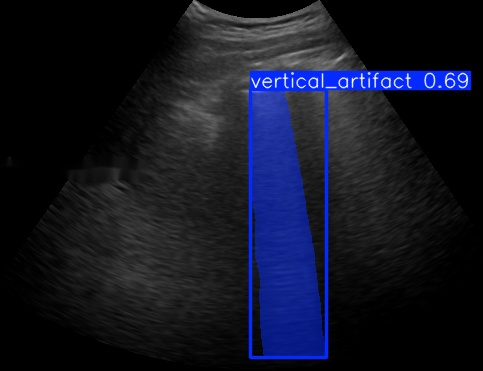

1646466986468.jpg


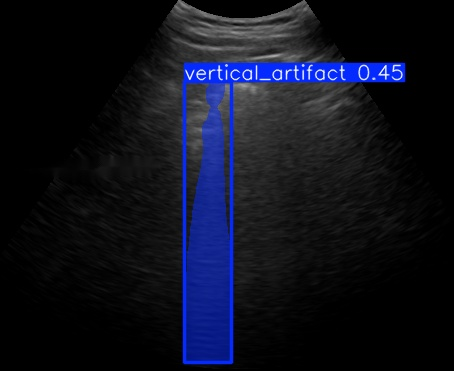

1646467055251.jpg


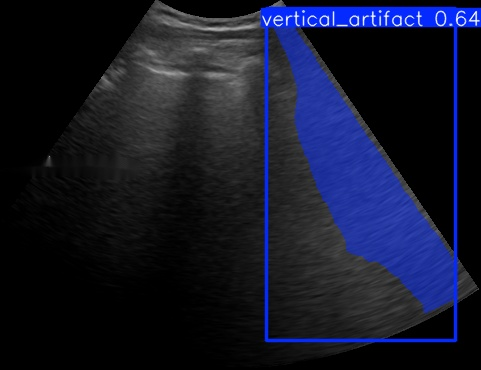

1646467098404.jpg


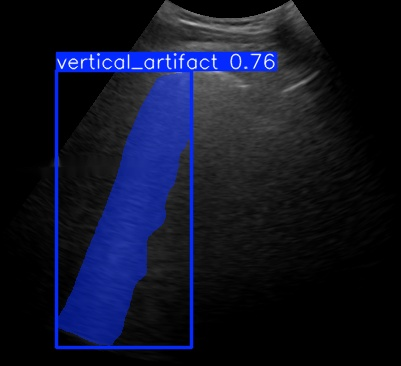

1646467165401.jpg


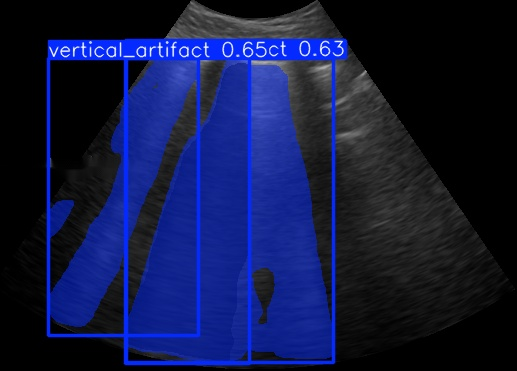

In [25]:
from pathlib import Path
from IPython.display import display, Image

pred_dir = Path(
    "/content/drive/MyDrive/lung_ultrasound_project/runs/"
    "lus_bald_val_predictions"
)

files = sorted(
    p for p in pred_dir.iterdir()
    if p.suffix.lower() in (".png", ".jpg", ".jpeg")
)

print("Saved prediction images:", len(files))

for p in files[:5]:
    print(p.name)
    display(Image(filename=str(p)))

val_batch0_labels.jpg


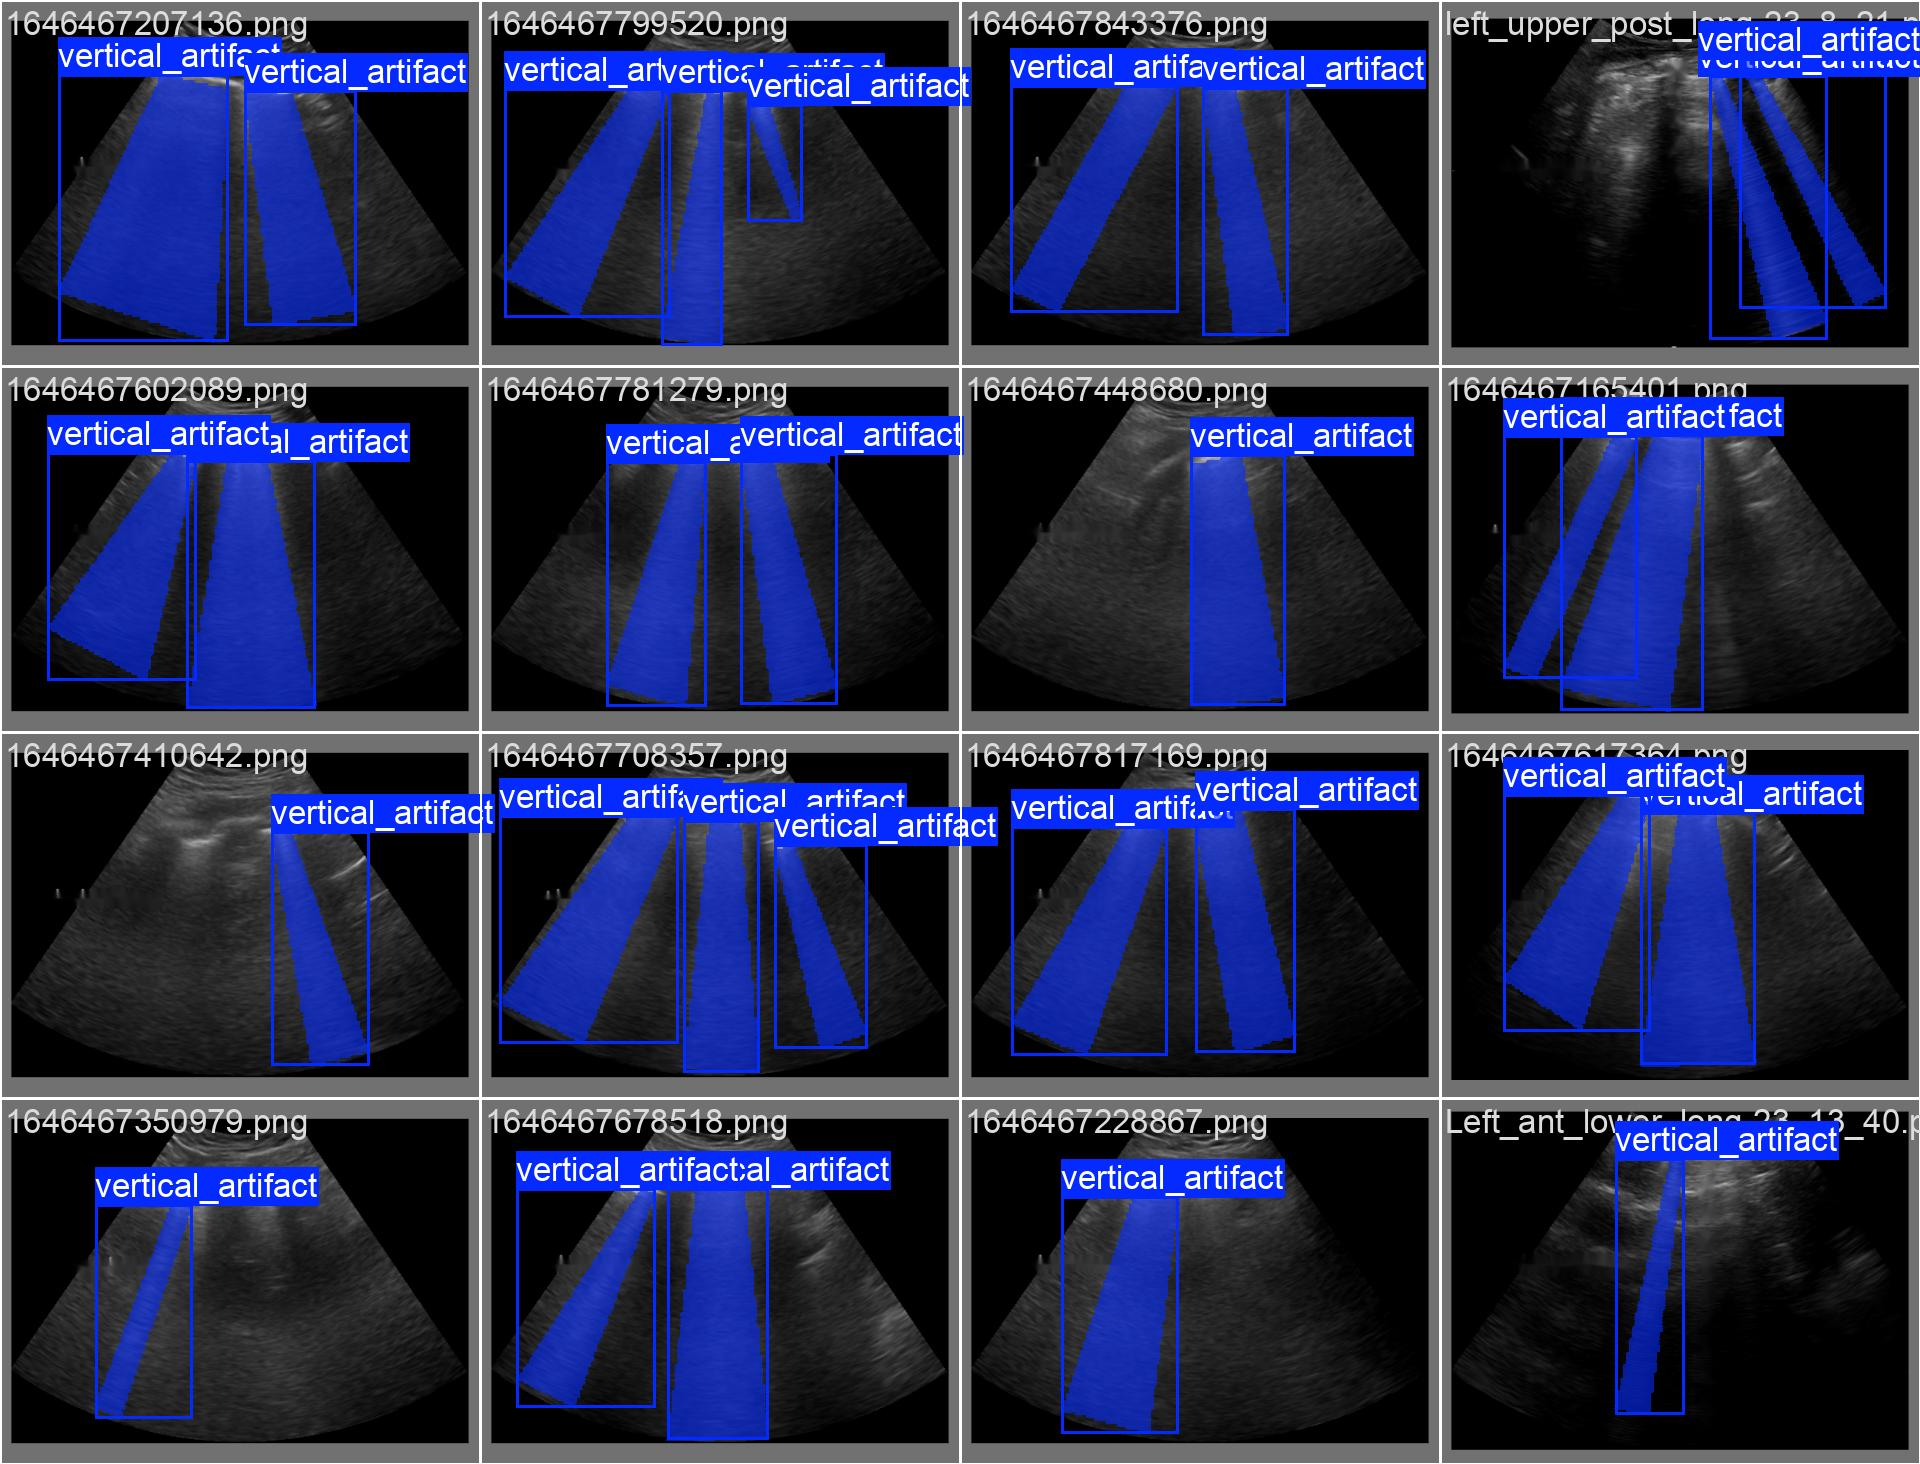

val_batch0_pred.jpg


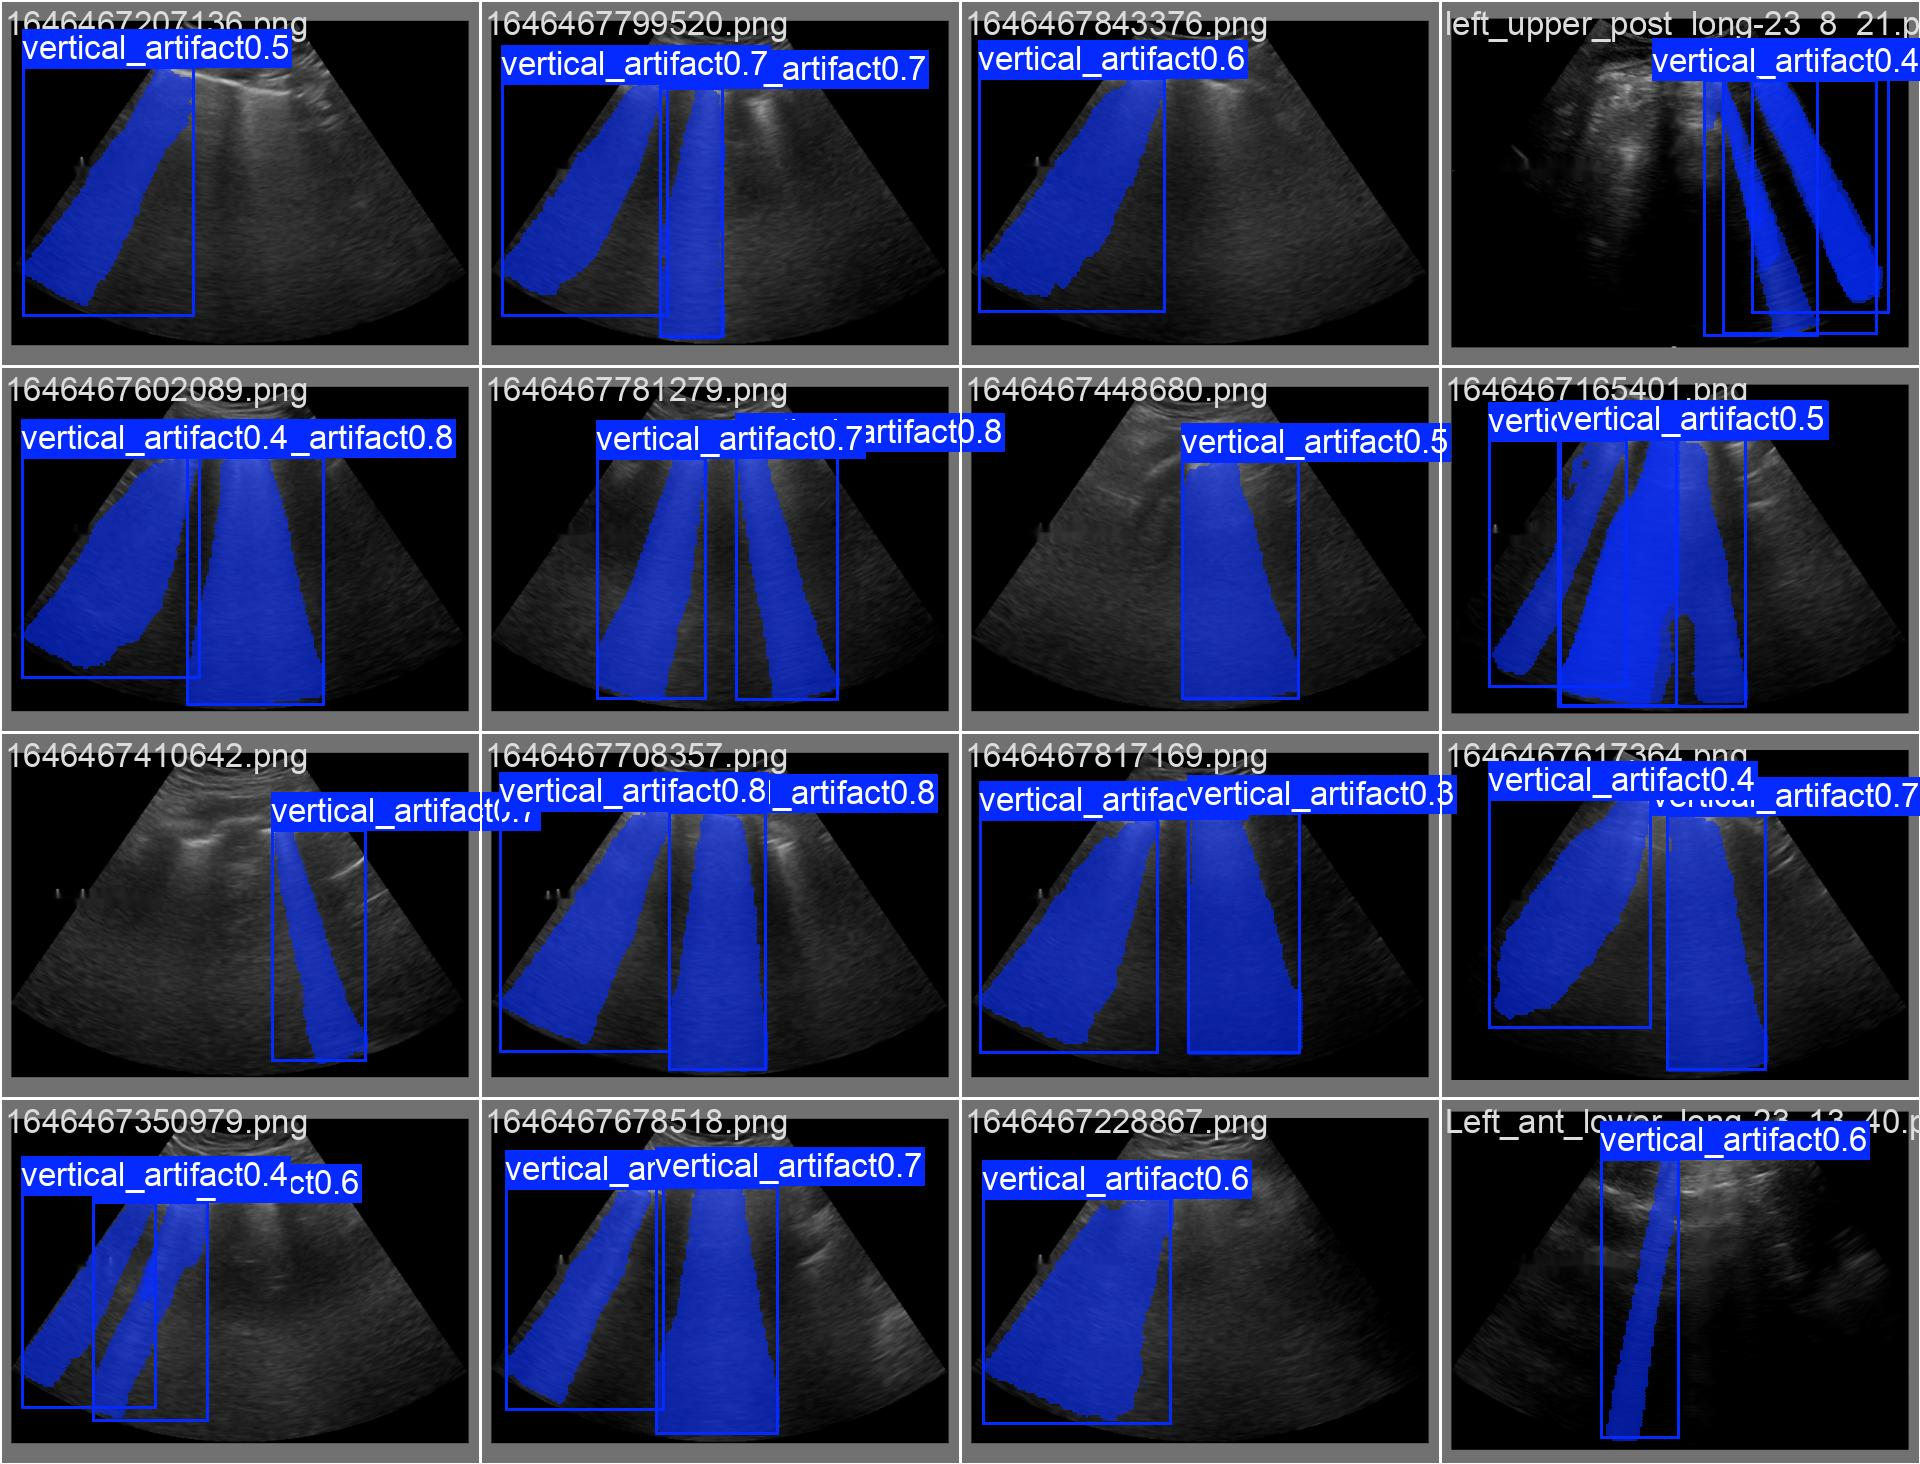

In [26]:
from IPython.display import display, Image

run_dir = "/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline"

for name in ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
    path = f"{run_dir}/{name}"
    print(name)
    display(Image(filename=path))

In [27]:
import os

for folder, _, files in os.walk(run_dir):
    for f in files:
        if f.endswith(".jpg"):
            print(os.path.join(folder, f))

/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/labels.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/train_batch0.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/train_batch1.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/train_batch2.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/train_batch1280.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/train_batch1281.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/train_batch1282.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/val_batch0_labels.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/val_batch0_pred.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/val_batch1_labels.jpg
/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/val_batch1_pred.jpg
/content/drive/MyDrive/l

val_batch0_labels.jpg


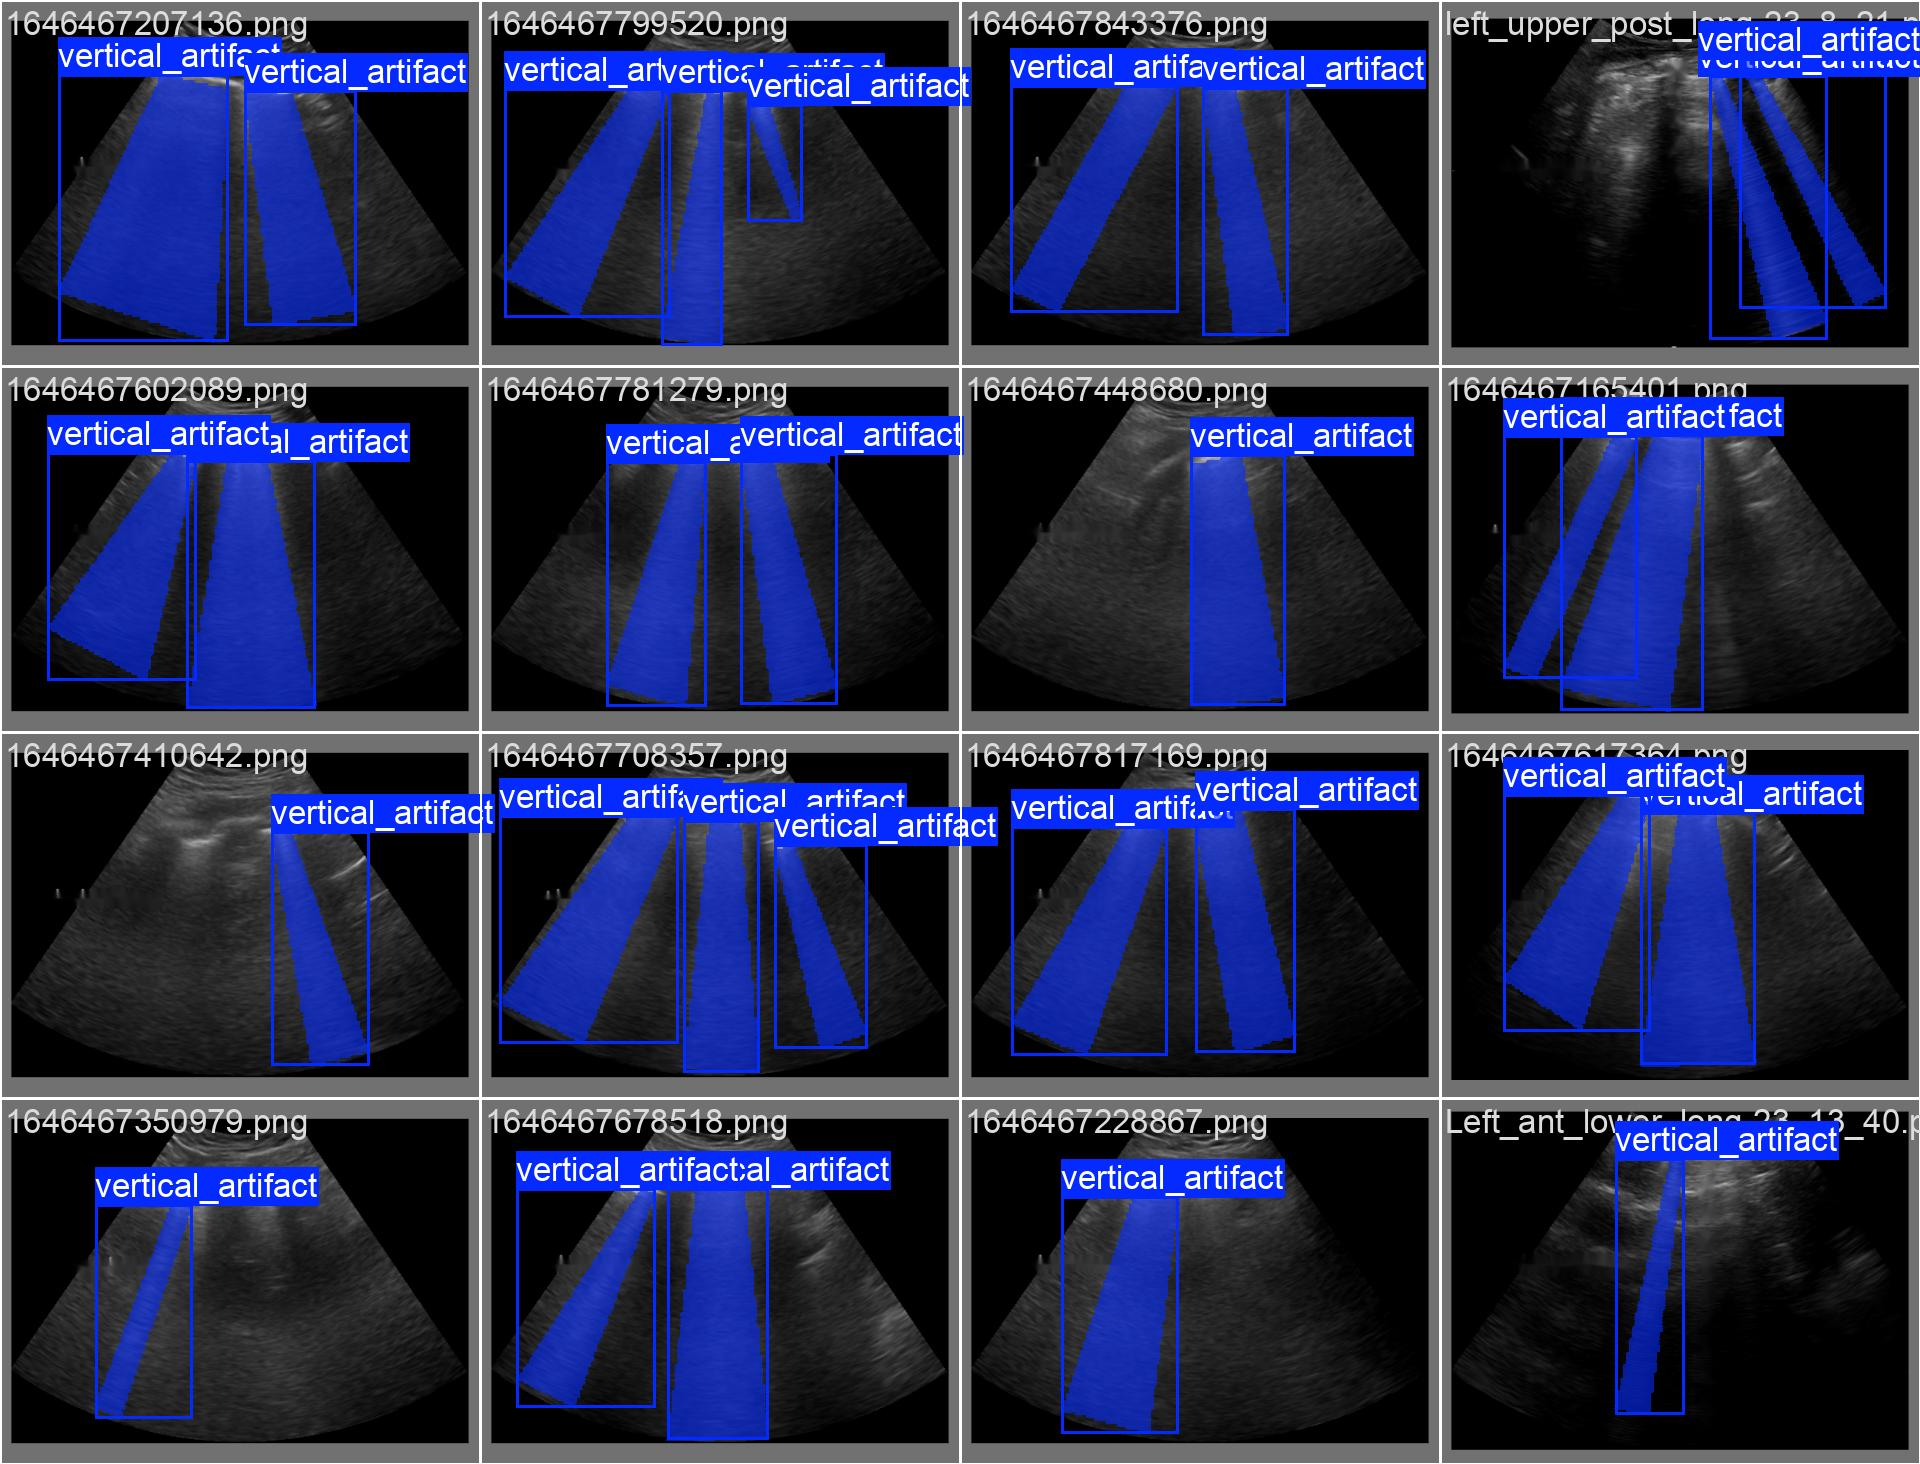

val_batch0_pred.jpg


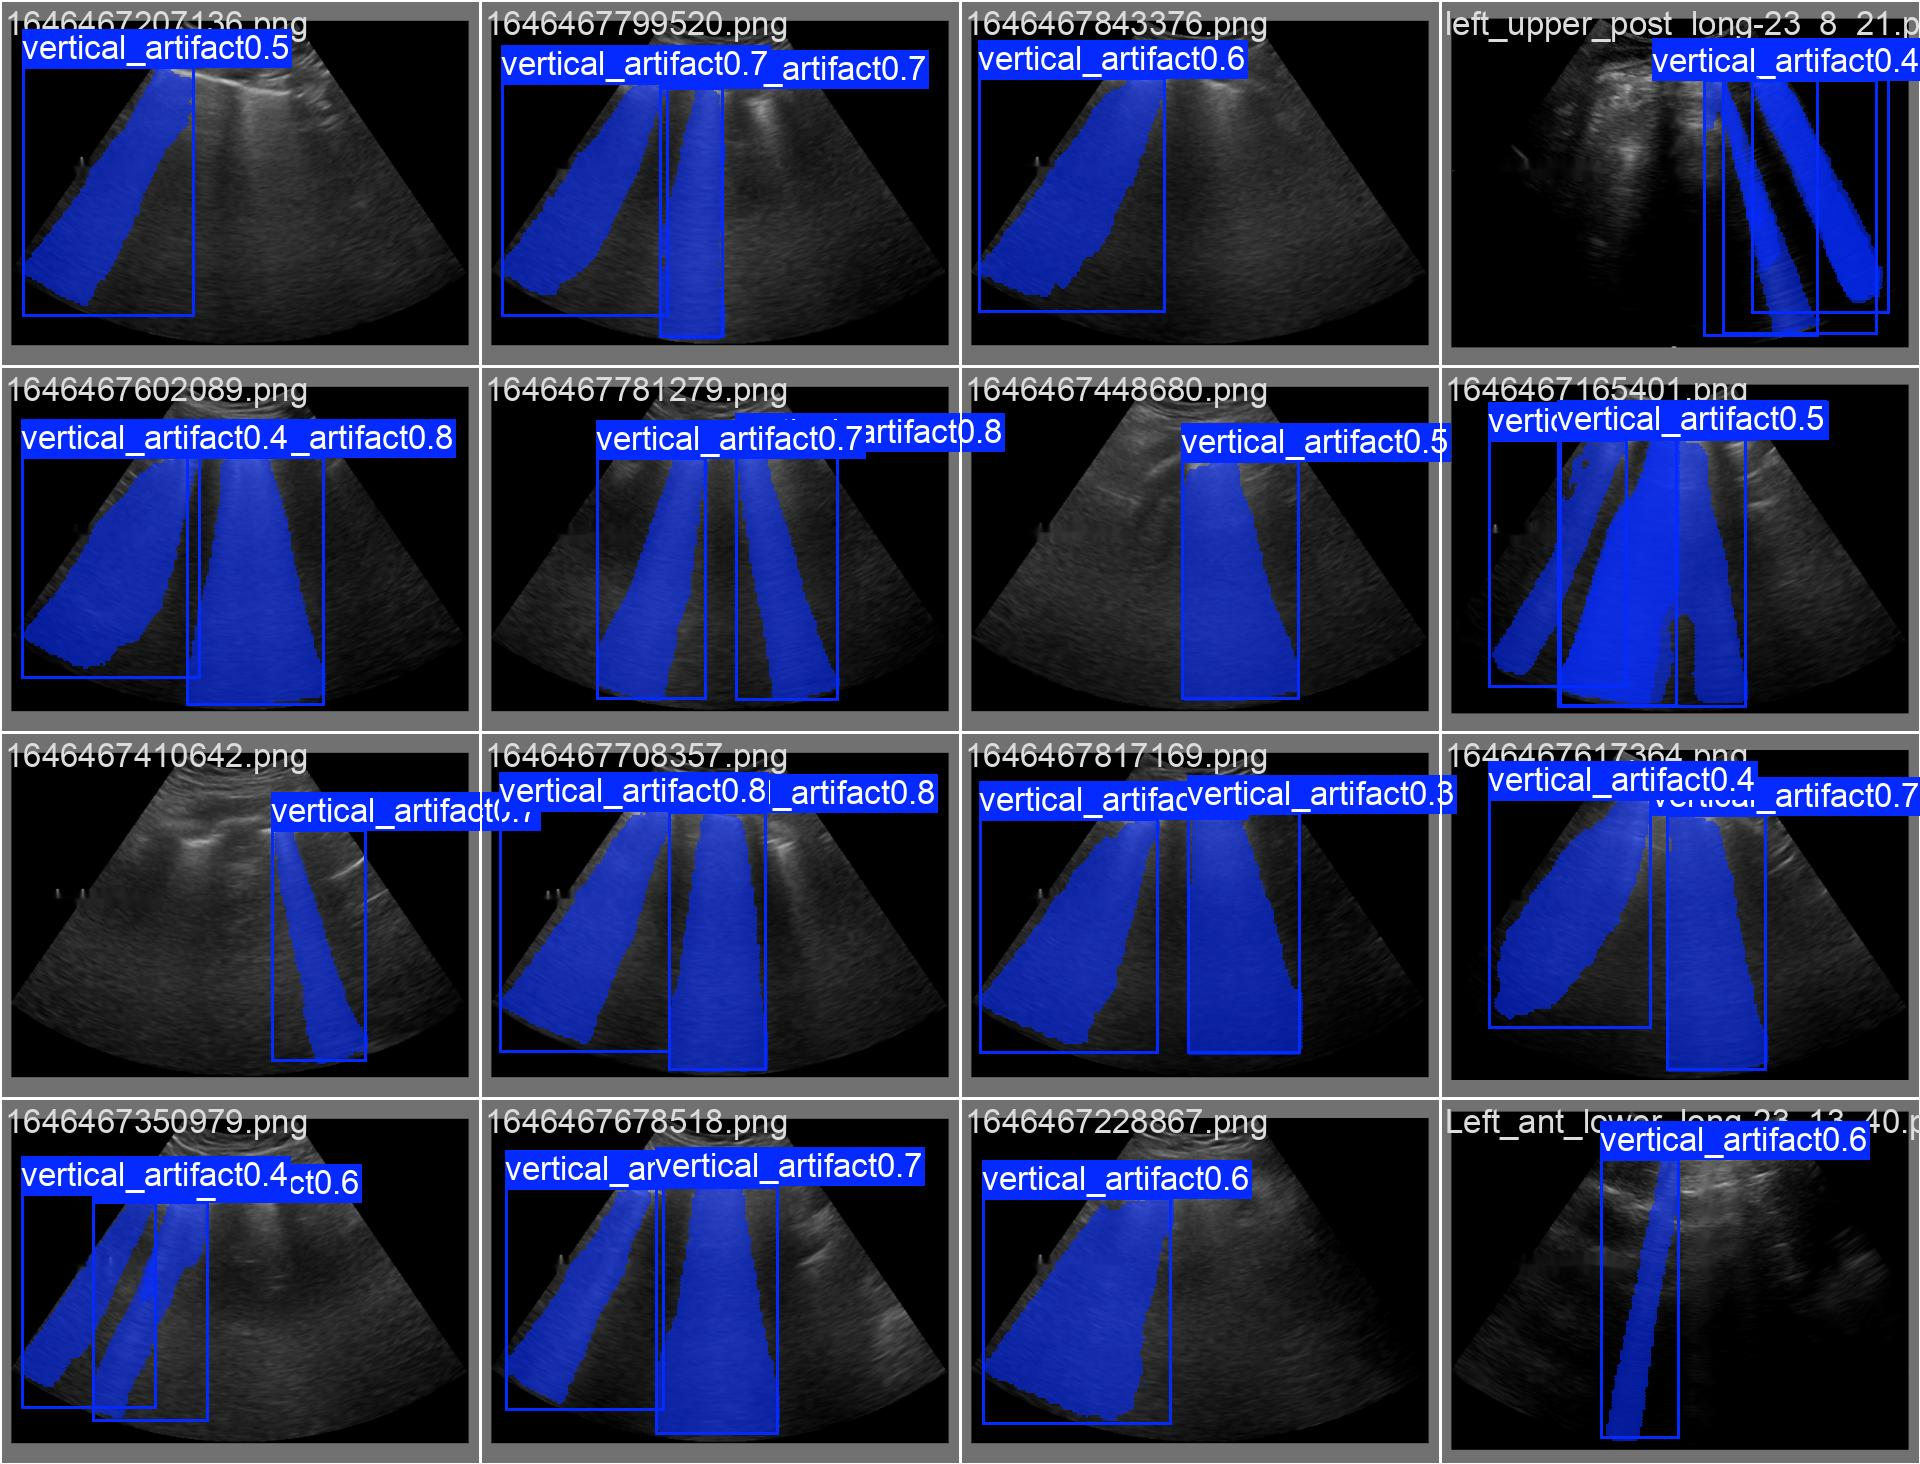

In [28]:
from IPython.display import display, Image

run_dir = "/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline"

for name in ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
    print(name)
    display(Image(filename=f"{run_dir}/{name}"))

In [29]:
from ultralytics import YOLO
from pathlib import Path

ROOT = Path("/content/LUS-BALD_extracted/LUS-BALD")
WEIGHTS = "/content/drive/MyDrive/lung_ultrasound_project/runs/lus_bald_baseline/weights/best.pt"

model = YOLO(WEIGHTS)

model.predict(
    source=str(ROOT / "test/images"),
    imgsz=640,
    conf=0.25,
    save=True,
    project="/content/drive/MyDrive/lung_ultrasound_project/runs",
    name="lus_bald_test_preview",
)


image 1/70 /content/LUS-BALD_extracted/LUS-BALD/test/images/1655892772231.png: 448x640 2 vertical_artifacts, 36.4ms
image 2/70 /content/LUS-BALD_extracted/LUS-BALD/test/images/1655892995530.png: 480x640 2 vertical_artifacts, 57.4ms
image 3/70 /content/LUS-BALD_extracted/LUS-BALD/test/images/1655893111232.png: 640x640 1 vertical_artifact, 16.2ms
image 4/70 /content/LUS-BALD_extracted/LUS-BALD/test/images/1655893126737.png: 640x512 1 vertical_artifact, 18.9ms
image 5/70 /content/LUS-BALD_extracted/LUS-BALD/test/images/1655893351430.png: 512x640 1 vertical_artifact, 19.8ms
image 6/70 /content/LUS-BALD_extracted/LUS-BALD/test/images/1655893369729.png: 608x640 3 vertical_artifacts, 18.7ms
image 7/70 /content/LUS-BALD_extracted/LUS-BALD/test/images/1655893391809.png: 448x640 1 vertical_artifact, 17.1ms
image 8/70 /content/LUS-BALD_extracted/LUS-BALD/test/images/1655893417199.png: 576x640 2 vertical_artifacts, 16.8ms
image 9/70 /content/LUS-BALD_extracted/LUS-BALD/test/images/1655893440062.p

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: ultralytics.engine.results.Masks object
 names: {0: 'vertical_artifact'}
 obb: None
 orig_img: array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        ...,
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]

In [30]:
import shutil
from pathlib import Path

source = Path(
    "/content/drive/MyDrive/lung_ultrasound_project/"
    "runs/lus_bald_baseline/weights/best.pt"
)
backup = Path(
    "/content/drive/MyDrive/lung_ultrasound_project/"
    "lus_bald_yolo11n_seg_best.pt"
)

shutil.copy2(source, backup)
print("Model backup saved:", backup)

Model backup saved: /content/drive/MyDrive/lung_ultrasound_project/lus_bald_yolo11n_seg_best.pt


In [31]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/lung_ultrasound_project/"
    "lus_bald_yolo11n_seg_best.pt"
)
onnx_path = model.export(format="onnx", imgsz=640)
print("Exported model:", onnx_path)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/lung_ultrasound_project/lus_bald_yolo11n_seg_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 37, 8400), (1, 32, 160, 160)) (5.7 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 313ms
Prepared 4 packages in 494ms
Installed 4 packages in 45ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: star

In [32]:
from ultralytics import YOLO

onnx_model = YOLO(
    "/content/drive/MyDrive/lung_ultrasound_project/"
    "lus_bald_yolo11n_seg_best.onnx"
)

onnx_model.predict(
    source="/content/LUS-BALD_extracted/LUS-BALD/val/images",
    imgsz=640,
    conf=0.25,
    save=True,
    project="/content/drive/MyDrive/lung_ultrasound_project/runs",
    name="lus_bald_onnx_check",
)

Loading /content/drive/MyDrive/lung_ultrasound_project/lus_bald_yolo11n_seg_best.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnxruntime-gpu'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 5 packages in 306ms
Prepared 1 package in 2.83s
Installed 1 package in 27ms
 + onnxruntime-gpu==1.31.0

requirements: AutoUpdate success ✅ 3.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Using ONNX Runtime 1.31.0 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...

image 1/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646466936258.png: 640x640 1 vertical_artifact, 149.9ms
image 2/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646466986468.png: 640x640 1 vertical_artifact, 144.5ms
image 3/75 /content/LUS-BALD_extracted/LUS-BALD/val/images/1646467055251.png: 640x640 1 vertical_artifact, 131.2ms
image 4/75 /content/LUS-BALD_ex

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: ultralytics.engine.results.Masks object
 names: {0: 'vertical_artifact'}
 obb: None
 orig_img: array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        ...,
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]